# Quantum Teleportation

Alice has a qubit in a state she doesn't know, and she wants Bob to have that exact state. She can't measure it without destroying it, and she can't copy it either, so Instead, she uses one shared entangled pair and two classical bits to move the exact state to Bob.

In [ ]:
!pip install -q qiskit qiskit-aer matplotlib pylatexenc

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator

sim = AerSimulator()
rng = np.random.default_rng()

### The mystery state
We create it by rotating a qubit to two random angles. we keep it so we can undo it later to check the result.

In [ ]:
theta = rng.uniform(0, np.pi)
phi = rng.uniform(0, 2 * np.pi)

def make_mystery(qc, qubit):
    qc.ry(theta, qubit)
    qc.rz(phi, qubit)

def undo_mystery(qc, qubit):
    qc.rz(-phi, qubit)
    qc.ry(-theta, qubit)

print(f"theta = {theta:.2f}, phi = {phi:.2f}")
print(f"chance of measuring 0: {np.cos(theta / 2) ** 2:.1%}")

theta = 2.12, phi = 1.58
chance of measuring 0: 24.0%


### The teleportation circuit
Qubit 0 holds the mystery state, and qubits 1 and 2 are an entangled pair shared by Alice and Bob. Alice applies a CNOT and an H, measures her two qubits, and sends the two bits to Bob. Bob applies X if the second bit is 1 and Z if the first bit is 1.

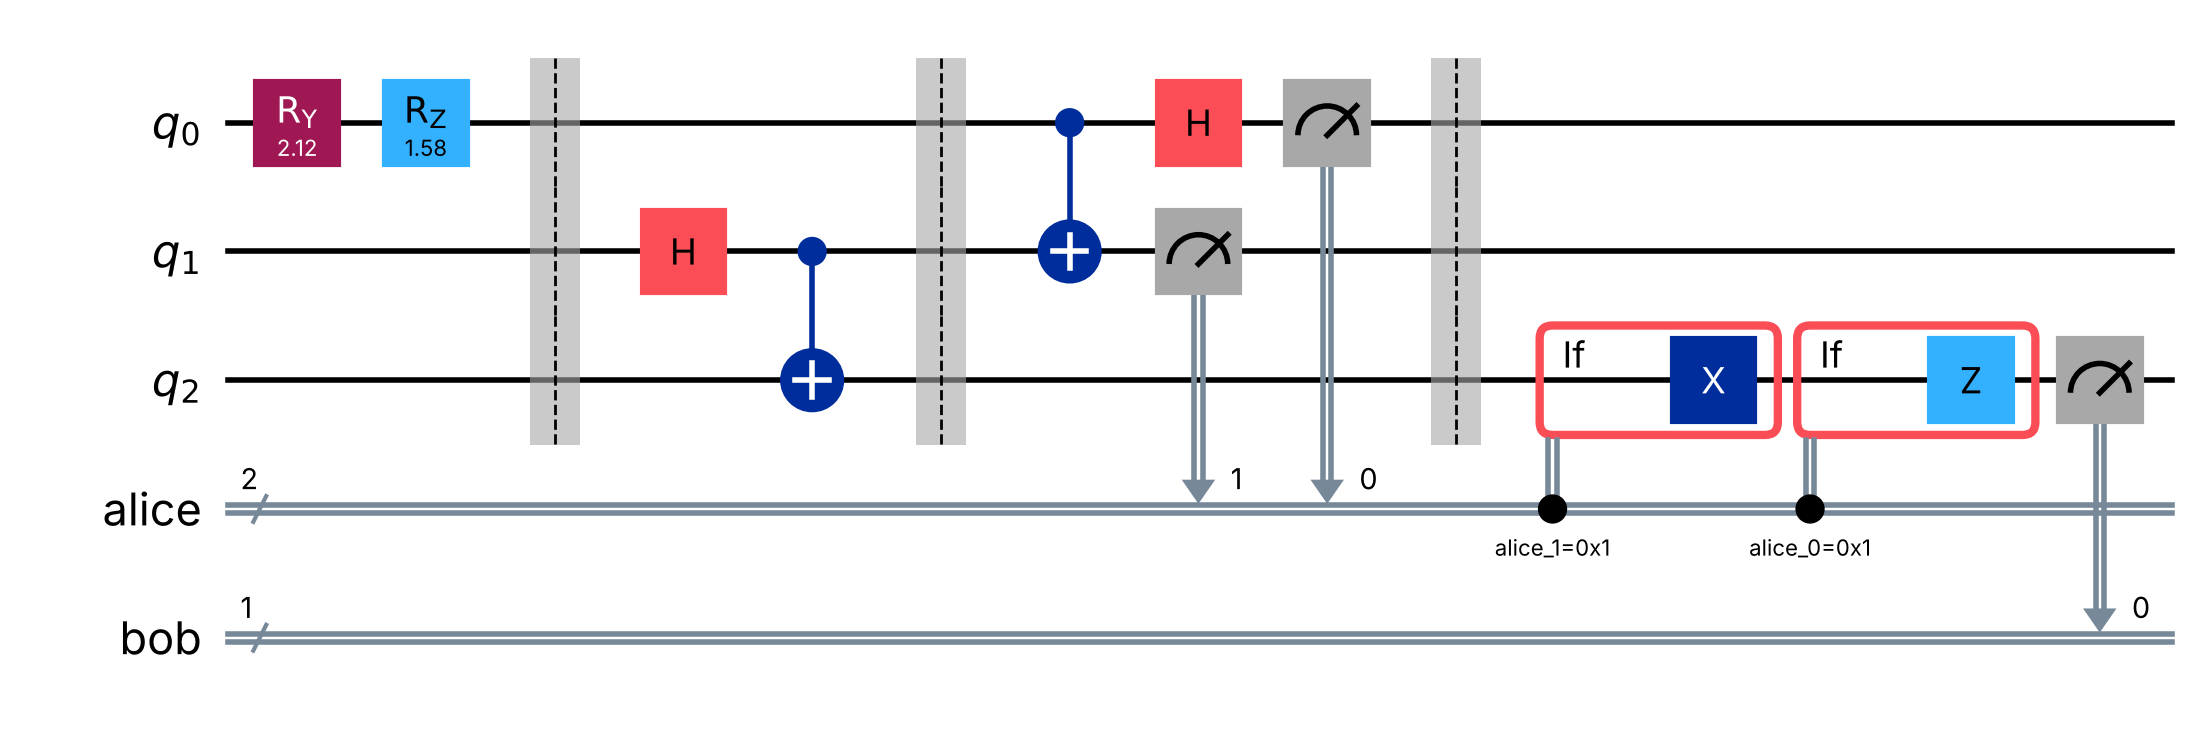

In [ ]:
def teleport(bob_fixes=True, check=False):
    qubits = QuantumRegister(3, "q")
    alice_bits = ClassicalRegister(2, "alice")
    bob_bit = ClassicalRegister(1, "bob")
    qc = QuantumCircuit(qubits, alice_bits, bob_bit)

    make_mystery(qc, 0)
    qc.barrier()

    qc.h(1)
    qc.cx(1, 2)
    qc.barrier()

    qc.cx(0, 1)
    qc.h(0)
    qc.measure(0, alice_bits[0])
    qc.measure(1, alice_bits[1])
    qc.barrier()

    if bob_fixes:
        with qc.if_test((alice_bits[1], 1)):
            qc.x(2)
        with qc.if_test((alice_bits[0], 1)):
            qc.z(2)

    if check:
        undo_mystery(qc, 2)
    qc.measure(2, bob_bit[0])
    return qc

teleport().draw("mpl", fold=-1)

The sections, separated by the dashed lines, are the mystery state, the entangled pair, Alice's operations, and Bob's fixes.

### First check: do the odds match?
If Bob has the mystery state, measuring his qubit should give 0 and 1 with the same odds as the original.

In [ ]:
def bob_counts(qc, shots=1000):
    counts = sim.run(transpile(qc, sim), shots=shots).result().get_counts()
    bob = {"0": 0, "1": 0}
    for key, n in counts.items():
        bob[key.split()[0]] += n
    return bob

original = QuantumCircuit(1, 1)
make_mystery(original, 0)
original.measure(0, 0)
original_counts = sim.run(transpile(original, sim), shots=1000).result().get_counts()
original_counts = {"0": original_counts.get("0", 0), "1": original_counts.get("1", 0)}

teleported_counts = bob_counts(teleport())

print(f"original:   {original_counts}")
print(f"teleported: {teleported_counts}")

original:   {'0': 233, '1': 767}
teleported: {'0': 235, '1': 765}


The odds match, but this only checks the size of the amplitudes and not their signs, so it isn't a full proof.

### Full check: undo what we did
If Bob's qubit is exactly the mystery state, reapplying what we applied in reverse turns it back into ket 0, and measuring gives 0 every time. Any error would produce some 1s.

As a control, we run it again without Bob's fixes, as if Alice's two bits never arrived.

In [ ]:
with_fixes = bob_counts(teleport(bob_fixes=True, check=True))
without_fixes = bob_counts(teleport(bob_fixes=False, check=True))

print(f"with Bob's fixes:    {with_fixes}")
print(f"without Bob's fixes: {without_fixes}")

with Bob's fixes:    {'0': 1000, '1': 0}
without Bob's fixes: {'0': 471, '1': 529}


### Results

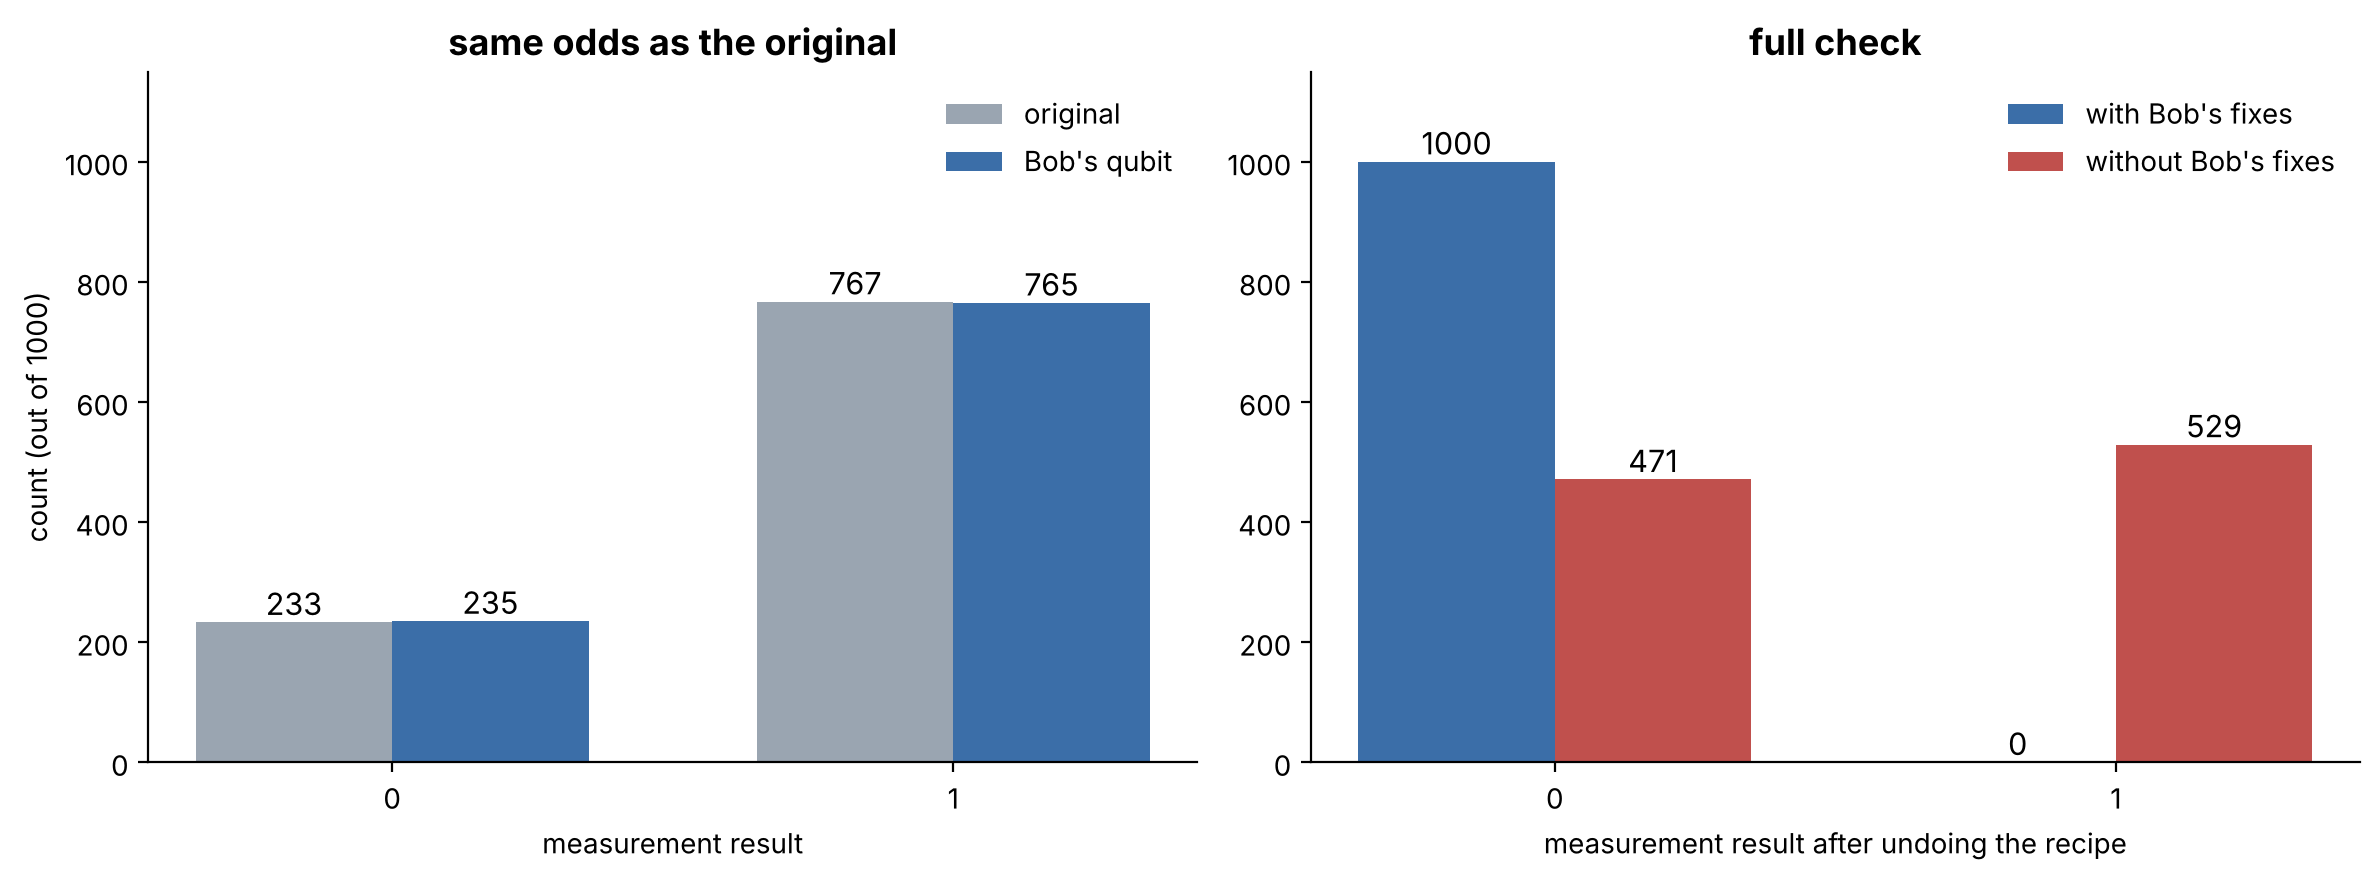

In [ ]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.5))
outcomes = ["0", "1"]
width = 0.35
x = np.arange(2)

b1 = left.bar(x - width / 2, [original_counts[o] for o in outcomes], width, label="original", color="#9aa5b1")
b2 = left.bar(x + width / 2, [teleported_counts[o] for o in outcomes], width, label="Bob's qubit", color="#3b6ea8")
left.bar_label(b1, fontsize=11)
left.bar_label(b2, fontsize=11)
left.set_xticks(x, outcomes)
left.set_ylim(0, 1150)
left.set_xlabel("measurement result")
left.set_ylabel("count (out of 1000)")
left.set_title("same odds as the original", fontsize=13, fontweight="bold")
left.legend(frameon=False)

b3 = right.bar(x - width / 2, [with_fixes[o] for o in outcomes], width, label="with Bob's fixes", color="#3b6ea8")
b4 = right.bar(x + width / 2, [without_fixes[o] for o in outcomes], width, label="without Bob's fixes", color="#c0504d")
right.bar_label(b3, fontsize=11)
right.bar_label(b4, fontsize=11)
right.set_xticks(x, outcomes)
right.set_ylim(0, 1150)
right.set_xlabel("measurement result after undoing the recipe")
right.set_title("full check", fontsize=13, fontweight="bold")
right.legend(frameon=False)

for ax in (left, right):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

With Bob's fixes, every result is 0, so the exact state arrived. Without them, Bob only has the right state when Alice's bits were 00, and the 1s show the state was scrambled the rest of the time.

### Notes
- The state is moved, not copied. Alice's original is destroyed when she measures.
- Nothing travels faster than light, because Bob's qubit is useless until Alice's two classical bits reach him.
- Alice's bits are completely random, so they reveal nothing about the state itself.
- Teleportation is a building block for quantum networks and for linking quantum processors.